In [1]:
import numpy as np
import pandas as pd
from io import StringIO
from scipy.spatial import cKDTree # create KDTree
import matplotlib.pyplot as plt

import fafbseg # API
from fafbseg import flywire
import caveclient

import networkx as nx # create tree based on SWC
import navis

import jax
import jaxley as jx
import jax.numpy as jnp # numpy in jax
from jaxley.channels import Na, K, Leak # Mechanism

from jax import config # Device
config.update("jax_platform_name", "gpu")


from jax import jit, vmap, value_and_grad # Simulation and optimization

In [ ]:
import optax
import tensorflow as tf
from tensorflow.data import Dataset
from collections import defaultdict


In [3]:
def bfs_relabel(skel):
    """
    Performs a breadth-first relabeling on a list of nodes with parent indices.
    :param node_list: A list of nodes, where each node is a tuple of the node index and its parent index.
    :return: A list of node indices visited during the search.
    """
    relabel = {}
    visited = []
    queue = [1]
    counter = 1 
    while queue:
        node_index = queue.pop(0)
        if node_index not in visited:
            visited.append(node_index)
            neighbors = list(skel.predecessors(node_index))
            queue.extend(neighbors)
            relabel[node_index] = counter
            counter += 1
    return relabel

def relabel_skeleton_swc(skel_graph, skel_df, row_name="rowId", link_name="link"):
    relabel_dict = bfs_relabel(skel_graph)
    relabel_dict[-1] = -1
    skel_df[row_name] = skel_df[row_name].map(relabel_dict)
    skel_df[link_name] = skel_df[link_name].map(relabel_dict)
    swc = "# rowId type x y z radius link\n"
    for i in range(skel_df.shape[0]):
        s = f"{int(skel_df.iloc[i][row_name])} 0 {skel_df.iloc[i].x} {skel_df.iloc[i].y} {skel_df.iloc[i].z} {skel_df.iloc[i].radius} {int(skel_df.iloc[i][link_name])}\n"
        swc += s
    return swc, relabel_dict

In [4]:
file_name = '720575940622997453.swc'
neuron_name = 'MBON-18'
root_id = 720575940622997453
mbon_skel = pd.read_csv(file_name, comment='#', delim_whitespace=True, header=None, names=['n', 'type', 'x', 'y', 'z', 'radius', 'parent'])
mbon_skel_edges = mbon_skel[mbon_skel['parent'] != -1].copy() # Create a copy of mbon_skel and remove the root node
mbon_skel_edges['parent'] = mbon_skel_edges['parent'].astype(int) # Convert the parent column to integer type
mbon_graph = nx.from_pandas_edgelist(mbon_skel_edges, 'n', 'parent', create_using=nx.DiGraph) # Create a networkx graph from mbon_skel_edges
mbon_swc, relabel_dict = relabel_skeleton_swc(mbon_graph, mbon_skel, row_name="n", link_name="parent")
mbon_swc_df = pd.read_csv(StringIO(mbon_swc), comment='#', delim_whitespace=True, header=None, names=['n', 'type', 'x', 'y', 'z', 'radius', 'parent'])
mbon_swc_df[['x', 'y', 'z', 'radius']] = mbon_swc_df[['x', 'y', 'z', 'radius']] / 1000 # everything in um

In [ ]:
soma = flywire.get_somas(root_id)
# Parameters
# Neuron diameter in drosophila is ~2um or ~2k nm
# All converted to um
volume = soma['volume'][0] #um
soma_pt = np.array((soma['pt_position'][0])/1000) #um
rad_est = (soma['rad_est'][0])/1000 #um
rad_arti = round(((3*volume)/(4*np.pi))**(1/3), 2) #um

In [85]:
# Soma replacement
in_bool = []
for i in range(mbon_swc_df.shape[0]):
    [x_seg, y_seg, z_seg] = np.array([mbon_swc_df.x.iloc[i], mbon_swc_df.y.iloc[i], mbon_swc_df.z.iloc[i]])
    seg_pt = np.array([x_seg, y_seg, z_seg])
    dist = np.linalg.norm(seg_pt - soma_pt)
    in_bool.append(dist <= rad_est + mbon_swc_df.radius.iloc[i]/1000) # T means in and removed
in_bool = np.array(in_bool)    
mbon_swc_df[in_bool]

mbon_swc_soma_df = mbon_swc_df[~in_bool].copy()
mbon_swc_soma_df['parent'].replace(mbon_swc_df[in_bool]['n'].tolist(), 1, inplace=True)
soma_row = pd.DataFrame({"n": [1], "type": [1], "x": [soma_pt[0]], "y": [soma_pt[1]], "z": [soma_pt[2]], "radius": [rad_arti], "parent": [-1]})
mbon_swc_soma_df = pd.concat([soma_row, mbon_swc_soma_df]).reset_index(drop=True)

rm_list = mbon_swc_df[in_bool]['n'].tolist()
rm_list

[1, 14, 13, 16, 15, 8, 9, 12, 10, 11, 6, 7, 2, 17, 5, 3, 4]

In [ ]:
sorted_df = mbon_swc_soma_df.sort_values(by=['n']).reset_index(drop=True)
n_to_index = pd.Series(sorted_df.index + 1, index=sorted_df['n']).to_dict()
n_to_index[-1] = -1
sorted_df['n'] = sorted_df.index + 1
sorted_df['parent'] = sorted_df['parent'].map(n_to_index)
sorted_df

def write_swc(df, filename):
    # df[['x', 'y', 'z', 'radius']] = df[['x', 'y', 'z', 'radius']] / 10
    df.loc[df['radius'] < 0.001, 'radius'] = 0.01
    print (df['radius'].abs().min())
    # Write to the SWC file, space-separated
    df.to_csv(filename, sep=' ', header=False, index=False)
fileName = neuron_name + '_final.swc'
write_swc(sorted_df, fileName)

In [8]:
cell = jx.read_swc("MBON-18_final.swc", ncomp=1)

In [11]:
cell.insert(Leak())
cell.set("Leak_gLeak", 9.0E-6)
cell.set("Leak_eLeak", -60.04)
cell.set("axial_resistivity", 100)
cell.set("capacitance", 0.7)
cell.set("v", -60.04)

In [ ]:
data = pd.read_excel("alpha2normalisedmean400ms (2).xlsx", header = None)
v_exp = data.iloc[1, 1:].values[::10][:-1]
v_exp = -60.04 * v_exp -60.04
v_exp = v_exp.tolist() # Jax only handles arrays
v_exp_np = np.array(v_exp)
v_exp = jnp.array(v_exp) # From array to jnp (Jax's version of ndarray)
print (len(v_exp_np))

In [13]:
# Assuming v_exp_np is your voltage data, and its length is N
N = len(v_exp_np)
time = np.arange(0.5, (N+1) * 0.5, 0.5)  # Create a time array based on the 0.05 sec interval

In [ ]:
net = jx.Network([cell for _ in range(1)])
net.delete_trainables()
net.make_trainable("Leak_gLeak")
net.make_trainable("axial_resistivity")
net.make_trainable("capacitance")
net.delete_recordings()
net.cell(0).branch(0).loc(0.5).record() # Center of soma

In [ ]:
params = net.get_parameters()
s = jx.integrate(net, params=params, t_max=459, delta_t = 0.5)

In [33]:
def simulate(params):
    currents = jx.datapoint_to_step_currents(i_delay=30.0, i_dur=400.0, i_amp= [-0.01], delta_t=0.5, t_max=460.0)

    data_stimuli = None
    data_stimuli = net.cell(0).branch(0).loc(0.5).data_stimulate(currents[0], data_stimuli=data_stimuli)

    return jx.integrate(net, params=params, data_stimuli=data_stimuli)

In [31]:
import jaxley.optimize.transforms as jt

In [32]:
transform = jx.ParamTransform([{"Leak_gLeak": jt.SigmoidTransform(1e-6, 1.2e-4)},
                               {"axial_resistivity":jt.SigmoidTransform(30, 400)},
                               {"capacitance" : jt.SigmoidTransform(0.6, 2.6)}])

In [ ]:
def loss(opt_params, v_exp):
    params = transform.forward(opt_params)
    v_sim = simulate(params)[0, 1:-1]  # Ensure this also returns a JAX array
    return jnp.mean((v_sim - v_exp)**2)  # sum of squared differences


# JIT compile the loss function and its gradient
jitted_grad = jit(value_and_grad(loss, argnums=0))

# Convert params to JAX arrays if they aren't already
value, gradient = jitted_grad(params, v_exp)  # Ensure v_exp is a JAX array here as well

In [ ]:
opt_params = transform.inverse(params)
optimizer = optax.adam(learning_rate=1)
opt_state = optimizer.init(opt_params)

In [ ]:
tf.random.set_seed(1)

In [ ]:
for epoch in range (40):
    epoch_loss = 0.0
    loss_val, gradient = jitted_grad(opt_params, v_exp)
    updates, opt_state = optimizer.update(gradient, opt_state)
    opt_params = optax.apply_updates(opt_params, updates)
    epoch_loss += loss_val
    print(f"epoch {epoch}, loss {epoch_loss}")
    
final_params = transform.forward(opt_params)

In [ ]:
cell.set("Leak_gLeak", final_params[0])
cell.set("Leak_eLeak", -60.04)
cell.set("axial_resistivity", final_params[1])
cell.set("capacitance", final_params[2])

In [9]:
datastack_name = "flywire_fafb_public"
client = caveclient.CAVEclient(datastack_name)

In [97]:
# What ids are KC
class_annos_df = client.materialize.query_table("hierarchical_neuron_annotations", filter_equal_dict={"classification_system": "cell_class", "cell_type": "Kenyon_Cell"})
# What cells are presyn to this MBON
postsyn_df = client.materialize.query_view("valid_synapses_nt_np_v6", filter_in_dict={"post_pt_root_id": [root_id]})
# Get presyn cells that are KC
KC_presyn_cells = postsyn_df[postsyn_df['pre_pt_root_id'].isin(class_annos_df['pt_root_id'])]
# KC_presyn_cells['post_pt_position'] is what we need
KC_presyn_cells

,id,pre_pt_root_id,post_pt_root_id,connection_score,cleft_score,gaba,ach,glut,oct,ser,da,valid_nt,pre_pt_supervoxel_id,post_pt_supervoxel_id,neuropil,pre_pt_position,post_pt_position
0,918285,720575940627097361,720575940622997453,690.144470,165,0.027637,0.260075,0.087501,0.000478,0.040238,0.584071,t,81137017664501663,81137017664501456,MB_VL_R,"[613320, 137640, 74880]","[613292, 137532, 74880]"
1,918473,720575940625570334,720575940622997453,757.010742,163,0.053902,0.400003,0.121363,0.003617,0.038654,0.382460,t,80996348895647212,80996348895657103,MB_VL_R,"[604932, 137884, 75280]","[604804, 137812, 75280]"
2,38915,720575940614899851,720575940622997453,864.926208,168,0.004994,0.002189,0.051190,0.000227,0.037170,0.904229,t,81066442761913372,81066442761906832,MB_VL_R,"[608284, 125128, 75160]","[608216, 125180, 75120]"
3,553972,720575940629022875,720575940622997453,432.047668,155,0.063886,0.413269,0.068484,0.000338,0.086190,0.367834,t,80995936578744239,80995936578743127,MB_VL_R,"[605288, 117108, 74120]","[605404, 117100, 74040]"
4,459750,720575940624107706,720575940622997453,264.122498,152,0.029377,0.084723,0.141119,0.001683,0.063906,0.679192,t,80996142737209040,80996142737231755,MB_VL_R,"[603372, 127016, 75120]","[603488, 127120, 75080]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6644,135691172,720575940607804939,720575940622997453,331.633881,155,0.025591,0.056017,0.654137,0.000006,0.043164,0.221085,t,80925773993098324,80925773993094262,SMP_R,"[600696, 128692, 75760]","[600696, 128572, 75760]"
6645,27828777,720575940641889952,720575940622997453,1524.358398,154,0.023805,0.774208,0.027258,0.000807,0.059207,0.114717,t,81137086383753672,81137086383757713,MB_VL_R,"[611864, 141552, 67320]","[611756, 141504, 67360]"
6647,183237312,720575940626668304,720575940622997453,372.679688,163,0.000463,0.012028,0.983069,0.000002,0.001344,0.003093,t,81137017664355112,81137017664346909,MB_VL_R,"[610012, 136364, 69120]","[610024, 136504, 69160]"
6649,27673953,720575940618547280,720575940622997453,44.533916,51,0.189771,0.071878,0.248834,0.006477,0.096769,0.386271,t,80996074017529840,80996074017539686,MB_VL_R,"[603008, 121544, 67880]","[603080, 121676, 67880]"


In [98]:
postsyn_df

,id,pre_pt_root_id,post_pt_root_id,connection_score,cleft_score,gaba,ach,glut,oct,ser,da,valid_nt,pre_pt_supervoxel_id,post_pt_supervoxel_id,neuropil,pre_pt_position,post_pt_position
0,918285,720575940627097361,720575940622997453,690.144470,165,0.027637,0.260075,0.087501,0.000478,4.023777e-02,5.840713e-01,t,81137017664501663,81137017664501456,MB_VL_R,"[613320, 137640, 74880]","[613292, 137532, 74880]"
1,918473,720575940625570334,720575940622997453,757.010742,163,0.053902,0.400003,0.121363,0.003617,3.865422e-02,3.824601e-01,t,80996348895647212,80996348895657103,MB_VL_R,"[604932, 137884, 75280]","[604804, 137812, 75280]"
2,38915,720575940614899851,720575940622997453,864.926208,168,0.004994,0.002189,0.051190,0.000227,3.717019e-02,9.042292e-01,t,81066442761913372,81066442761906832,MB_VL_R,"[608284, 125128, 75160]","[608216, 125180, 75120]"
3,553972,720575940629022875,720575940622997453,432.047668,155,0.063886,0.413269,0.068484,0.000338,8.618969e-02,3.678338e-01,t,80995936578744239,80995936578743127,MB_VL_R,"[605288, 117108, 74120]","[605404, 117100, 74040]"
4,459750,720575940624107706,720575940622997453,264.122498,152,0.029377,0.084723,0.141119,0.001683,6.390578e-02,6.791919e-01,t,80996142737209040,80996142737231755,MB_VL_R,"[603372, 127016, 75120]","[603488, 127120, 75080]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6648,222474189,720575940611090244,720575940622997453,570.827271,141,0.999931,0.000018,0.000049,0.000002,6.637496e-09,5.445984e-08,t,81207180384454225,81207180384441889,SIP_R,"[614416, 124052, 114680]","[614408, 124164, 114640]"
6649,27673953,720575940618547280,720575940622997453,44.533916,51,0.189771,0.071878,0.248834,0.006477,9.676853e-02,3.862706e-01,t,80996074017529840,80996074017539686,MB_VL_R,"[603008, 121544, 67880]","[603080, 121676, 67880]"
6650,179619886,720575940617749538,720575940622997453,50.254208,55,0.996601,0.000156,0.003142,0.000004,9.208995e-06,8.830612e-05,t,81207111531024091,81207111531020338,MB_VL_R,"[617444, 117712, 81720]","[617536, 117816, 81800]"
6651,28121255,720575940615696070,720575940622997453,355.989075,157,0.037436,0.038224,0.096215,0.000228,6.275287e-02,7.651443e-01,t,80996486334353960,80996486334360479,CRE_R,"[604240, 149960, 67720]","[604096, 149920, 67680]"


In [ ]:
cell.xyzr

In [ ]:
ind = 0
length = 0
for i, comp in enumerate(cell.xyzr):
    if (len(comp) > length):
        ind = i
        length = len(comp)
        print ("compartment", i, "has length", length)
ind

In [ ]:
len(cell.xyzr[1])

In [ ]:
def comp_length (i):
    comp = cell.xyzr[i]
    if (len(comp) == 1):
        return comp[0][-1]
    else:
        start_node = comp[0][:-1]
        length = 0
        for node in comp:
            end_node = node[:-1]
            length += np.sqrt(np.sum((start_node - end_node) ** 2))
            start_node = end_node
        return length

print (comp_length(0))
print (comp_length(76))

In [83]:
def node_comp (target): # target number
    target = sorted_df.iloc[target][['x', 'y', 'z', 'radius']].to_numpy()
    for comp_num, comp in enumerate (cell.xyzr):
        for index, node in enumerate (comp):
            if (np.allclose(target, node, rtol=1e-3, atol=1e-6)):
                return comp_num, index
    return -1, -1  

In [76]:
def node_loc (target):
    comp_num, index = node_comp(target)
    comp = cell.xyzr[comp_num]
    if (len(comp) == 1):
        return 0.5
    else:
        start_node = comp[0][:-1]
        end_node = comp[index][:-1]
        return comp_num, (np.sqrt(np.sum((start_node - end_node) ** 2)) / comp_length (comp_num))

In [99]:
def match_synapses_to_tree(synapses, skeleton_df):
    skel_coords = skeleton_df[['x', 'y', 'z']].to_numpy()
    synapses_coords = np.vstack(synapses['post_pt_position']) / 1000
    skel_tree = cKDTree(skel_coords)
    indx = skel_tree.query(synapses_coords)[1] # of skeleton
    return indx
    

indx = match_synapses_to_tree(postsyn_df, sorted_df)
print (indx) # Nodes nearest to a synapse
print (len(indx)) # Matching number of total synapses (see the df)

[26981 14709 18536 ...  3711 25922  4478]
6653


In [100]:
mbon_skel = pd.read_csv(fileName, comment='#', delim_whitespace=True, header=None, names=['n', 'type', 'x', 'y', 'z', 'radius', 'parent'])
mbon_skel_edges = mbon_skel[mbon_skel['parent'] != -1].copy()
mbon_skel_edges['parent'] = mbon_skel_edges['parent'].astype(int)
tree = nx.from_pandas_edgelist(mbon_skel_edges, 'parent', 'n', create_using=nx.DiGraph)

In [101]:
ancestor_sets = [nx.ancestors(tree, node) | {node} for node in indx]
parent = max(set.intersection(*ancestor_sets))
parent

735

In [103]:
PN_loc = node_comp(parent)
print (PN_loc)

(105, 1)


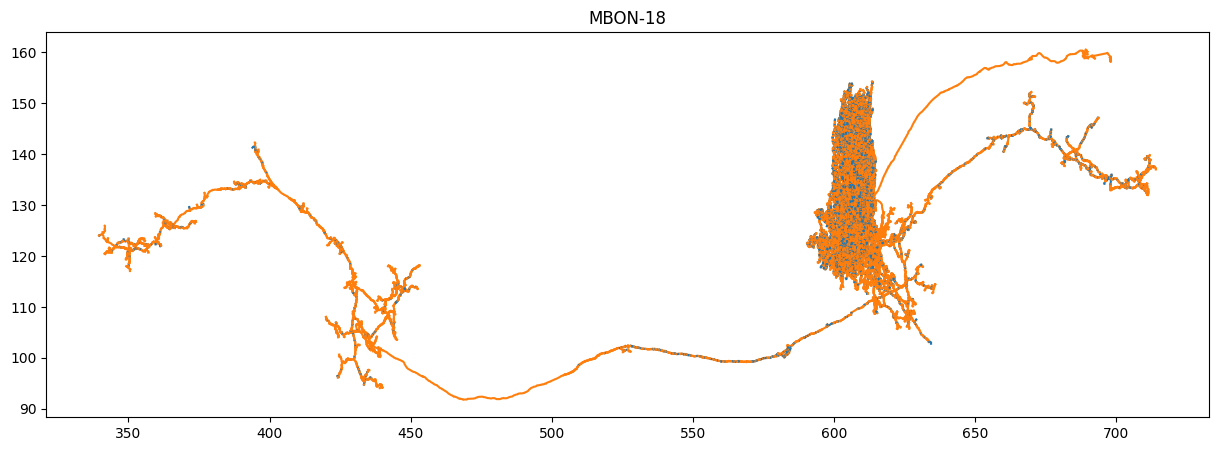

In [104]:
fig, ax = plt.subplots(1, 1, figsize=(15, 5))
# define colorwheel with 10 colors
colors = plt.cm.tab10.colors
for i, branch in enumerate(cell.branches):
    if (i in indx):
        branch.vis(ax=ax, col=colors[0])
    else:
        branch.vis(ax=ax, col=colors[1])

plt.title("MBON-18")
plt.show()